# 1.2 - Severity modelling: finding the best model

Goal: predict `grave` (serious / fatal accident) from the structured columns of
`data_clean/accidentes_clean.csv`, after dropping non-traffic rows with
`vehiculos_implicados == 0`.

Pipeline:

1. Rebuild features (cyclic hour, categorical month/weekday, moto×night interaction).
2. Stratified 80/20 split (seed 42).
3. Compare seven models with repeated CV (LogReg, ExtraTrees, EBM, RF, LightGBM, CatBoost, NB).
4. Feature ablation (baseline features vs full set) on LogReg.
5. Pick the best by PR-AUC; set a recall-targeted threshold from OOF (median over repeats).
6. Single test evaluation + bootstrap CI.
7. Interpret: permutation importance (test), LogReg odds ratios, EBM terms.

Metric: **PR-AUC** (average precision). Base rate ≈ 2 %. Accuracy is useless.
Report: headline = CV PR-AUC of the best model; explain with LogReg / EBM.

In [ ]:
from __future__ import annotations

import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 42
TARGET = "grave"

ROOT = Path.cwd()
while ROOT.name and not (ROOT / "data_clean" / "accidentes_clean.csv").exists():
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
RAW = ROOT / "data_clean" / "accidentes_clean.csv"
assert RAW.exists(), f"could not locate accidentes_clean.csv from {Path.cwd()}"
print("loading:", RAW)
raw = pd.read_csv(RAW)
print("raw shape:", raw.shape, "| severe:", int(raw[TARGET].sum()),
      f"({100 * raw[TARGET].mean():.2f} %)")

loading: /Users/lukas/dev/UC3M/Project-UC3M/data_clean/accidentes_clean.csv
raw shape: (1962, 26) | severe: 45 (2.29 %)


## 1. Feature rebuild

**Filter.** Drop rows with `vehiculos_implicados == 0` (cancelled alerts, pedestrian
precipitations, etc. — not vehicle traffic accidents). That removes 17 rows / 6 severe.

**Baseline features** (from `feature_engineering.ipynb`): `franja_horaria`, `con_moto`,
`con_pesado`, `carretera_grupo`, plus the original categoricals and counts.

**Extra features:**

- `hora_sin`, `hora_cos` — hour on a circle (23:50 sits next to 00:10).
- `mes_cat`, `dia_semana_cat` — month and weekday as **categories** (not integers).
- `es_fin_de_semana`, `fuera_de_madrid`.
- `moto_noche` — interaction: motorcycle × night (for linear models).
- `alcance_tronco` — rear-end collision on a main carriageway (TRONCO).

**Dropped as leakage / free text / dead:** `heridos_*`, `victimas_mortales`,
`descripcion`, IDs, `tipo_colision_inferido`, and `vehiculos_cero` (always 0 after the filter).

In [ ]:
LEAKAGE = {
    "heridos_leves", "heridos_graves", "victimas_mortales",
    "numero_incidencia", "localizacion", "eje", "unidad_samur_id",
    "descripcion", "tipo_colision_inferido",
}

# Baseline set (comparable to exploration_baselines.ipynb, minus distrito by default
# in the ablation; here we keep distrito in the full set).
CAT_BASE = ["tipo_colision", "estado_firme", "tipo_via", "ubicacion",
            "tipo_accidente", "circulacion", "distrito"]
CAT_DERIVED = ["franja_horaria", "carretera_grupo", "mes_cat", "dia_semana_cat"]
CAT_COLS = CAT_BASE + CAT_DERIVED
BIN_COLS = ["con_moto", "con_pesado", "fuera_de_madrid", "es_fin_de_semana",
            "moto_noche", "alcance_tronco"]
NUM_COLS = ["vehiculos_implicados", "motos_implicadas", "pesados_implicados",
            "hora_decimal", "hora_sin", "hora_cos"]
FEATURE_COLS = CAT_COLS + BIN_COLS + NUM_COLS

# Baseline-only feature set for the ablation (no cyclic hour, no calendar cats,
# no interactions; keep franja + flags + counts as in the M3 baselines).
BASELINE_CAT = ["tipo_colision", "estado_firme", "tipo_via", "ubicacion",
                "tipo_accidente", "circulacion", "franja_horaria", "carretera_grupo"]
BASELINE_NUM = ["vehiculos_implicados", "con_moto", "con_pesado", "hora_decimal"]

BIG_CARRETERAS = {"M30", "A2", "M607", "A5", "A4", "M11", "A3"}


def _franja(h):
    if pd.isna(h):
        return np.nan
    if h >= 22 or h < 6:
        return "noche"
    if h < 12:
        return "manana"
    if h < 18:
        return "tarde"
    return "tarde-noche"


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df.drop(columns=[c for c in LEAKAGE if c in df.columns and c != TARGET])

    df["carretera_grupo"] = df["carretera"].where(df["carretera"].isin(BIG_CARRETERAS), "Other")
    df["franja_horaria"] = df["hora_decimal"].apply(_franja)
    df["hora_sin"] = np.sin(2 * np.pi * df["hora_decimal"] / 24.0)
    df["hora_cos"] = np.cos(2 * np.pi * df["hora_decimal"] / 24.0)

    fecha = pd.to_datetime(df["fecha"], errors="coerce")
    dia = fecha.dt.day_of_week.astype("Int64").fillna(-1).astype(int)
    mes = fecha.dt.month.astype("Int64").fillna(-1).astype(int)
    df["dia_semana"] = dia
    df["mes"] = mes
    df["dia_semana_cat"] = dia.astype(str)
    df["mes_cat"] = mes.astype(str)
    df["es_fin_de_semana"] = (dia >= 5).astype(int)

    df["con_moto"] = (df["motos_implicadas"].fillna(0) >= 1).astype(int)
    df["con_pesado"] = (df["pesados_implicados"].fillna(0) >= 1).astype(int)
    df["fuera_de_madrid"] = df["fuera_de_madrid"].astype(int)

    # Interactions for linear models (trees can discover these themselves).
    df["moto_noche"] = (df["con_moto"] * (df["franja_horaria"] == "noche")).astype(int)
    df["alcance_tronco"] = (
        (df["tipo_colision"].str.upper().fillna("").str.contains("ALCANCE"))
        & (df["tipo_via"].fillna("").str.upper() == "TRONCO")
    ).astype(int)

    return df


assert not (LEAKAGE & set(FEATURE_COLS)), "leakage column in feature list"

df = build_features(raw)
# Drop non-traffic rows (zero vehicles).
n_before = len(df)
df = df[df["vehiculos_implicados"].fillna(-1) != 0].copy()
print(f"dropped {n_before - len(df)} rows with vehiculos_implicados == 0 "
      f"({n_before} → {len(df)}; severe left: {int(df[TARGET].sum())})")

X_all = df[FEATURE_COLS].copy()
y_all = df[TARGET].astype(int).values
print("features:", X_all.shape, "| columns:", len(FEATURE_COLS))
X_all.head(2)

dropped 17 rows with vehiculos_implicados == 0 (1962 → 1945; severe left: 39)
features: (1945, 23) | columns: 23


,tipo_colision,estado_firme,tipo_via,ubicacion,tipo_accidente,circulacion,distrito,franja_horaria,carretera_grupo,mes_cat,dia_semana_cat,con_moto,con_pesado,fuera_de_madrid,es_fin_de_semana,moto_noche,alcance_tronco,vehiculos_implicados,motos_implicadas,pesados_implicados,hora_decimal,hora_sin,hora_cos
0,COLISIÓN POR ALCANCE,Seco y limpio,VIA DE SERVICIO,SUPERFICIE,Colision entre vehiculos,NaN,CENTRO,noche,M30,1,0,0,0,0,0,0,0,4.0,0.0,0.0,1.5133,0.385898,0.922541
1,COLISIÓN POR ALCANCE,Seco y limpio,VIA DE SERVICIO,SUPERFICIE,Colision entre vehiculos,FLUIDA,USERA,noche,M30,1,0,0,0,0,0,0,0,2.0,0.0,0.0,1.9881,0.497300,0.867579


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE
)


def collapse_rare(train: pd.DataFrame, test: pd.DataFrame, cols, min_count=20):
    train = train.copy()
    test = test.copy()
    for c in cols:
        vc = train[c].value_counts(dropna=False)
        keep = set(vc[vc >= min_count].index.tolist())
        train[c] = train[c].where(train[c].isin(keep), "Other")
        test[c] = test[c].where(test[c].isin(keep), "Other")
    return train, test


X_train, X_test = collapse_rare(X_train, X_test, CAT_COLS)

assert int(y_train.sum()) + int(y_test.sum()) == int(y_all.sum()), \
    f"split lost positives: train={y_train.sum()} test={y_test.sum()} total={y_all.sum()}"
print(f"train: {X_train.shape} | positives: {int(y_train.sum())} ({100 * y_train.mean():.2f} %)")
print(f"test:  {X_test.shape} | positives: {int(y_test.sum())} ({100 * y_test.mean():.2f} %)")

POS_WEIGHT = (y_train == 0).sum() / max(int(y_train.sum()), 1)
BASE_RATE = float(y_train.mean())
print(f"scale_pos_weight (reference): {POS_WEIGHT:.2f}")
print(f"base rate: {BASE_RATE:.4f}")

train: (1556, 23) | positives: 31 (1.99 %)
test:  (389, 23) | positives: 8 (2.06 %)
scale_pos_weight (reference): 49.19
base rate: 0.0199


## 2. Evaluation helpers

All candidates use the **same folds** so paired comparisons are meaningful.

- `repeated_cv`: per-fold PR-AUC / ROC-AUC + per-repeat OOF probability matrix.
- Thresholds: **median** of the recall-targeted threshold across repeats (more stable
  than using a single repeat).
- `bootstrap_ci` for the test PR-AUC.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             brier_score_loss)

N_SPLITS = 5
N_REPEATS_SELECT = 10   # 5x10 = 50 folds for final ranking (more stable with ~31 positives)
N_REPEATS_QUICK = 5     # 5x5 for the ablation / quick checks


def shared_cv(n_repeats: int, seed: int = RANDOM_STATE):
    return RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=n_repeats, random_state=seed)


def repeated_cv(make_model, X, y, n_repeats=N_REPEATS_SELECT, seed=RANDOM_STATE):
    """Return per-fold PR-AUC (ap) and ROC-AUC (roc) plus per-repeat OOF probabilities."""
    cv = shared_cv(n_repeats, seed)
    ap, roc = [], []
    n = len(y)
    oof = np.full((n_repeats, n), np.nan)
    for i, (tr, va) in enumerate(cv.split(X, y)):
        repeat = i // N_SPLITS
        model = clone(make_model()) if callable(make_model) else clone(make_model)
        model.fit(X.iloc[tr], y[tr])
        p = model.predict_proba(X.iloc[va])[:, 1]
        oof[repeat, va] = p
        ap.append(average_precision_score(y[va], p))
        roc.append(roc_auc_score(y[va], p))
    return np.array(ap), np.array(roc), oof


def pooled_oof_ap(y, oof):
    return float(np.mean([average_precision_score(y, oof[r]) for r in range(oof.shape[0])]))


def recall_threshold(y, p, target_recall=0.75):
    """Highest threshold whose recall on the given probabilities is >= target_recall."""
    prec, rec, thr = precision_recall_curve(y, p)
    ok = rec[:-1] >= target_recall
    if not ok.any():
        return float(thr.min())
    return float(thr[ok][-1])


def median_recall_threshold(y, oof, target_recall=0.75):
    """Median of per-repeat recall-targeted thresholds (more stable than one repeat)."""
    thrs = [recall_threshold(y, oof[r], target_recall=target_recall)
            for r in range(oof.shape[0])]
    return float(np.median(thrs)), thrs


def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(thr[i]), float(f1[i])


def bootstrap_metric(y, p, metric, n=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    p = np.asarray(p)
    out = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].sum() == 0:
            continue
        out.append(metric(y[idx], p[idx]))
    lo, hi = np.percentile(out, [2.5, 97.5])
    return float(lo), float(hi), out

## 3. Pipelines

- `pre_ohe`: impute + one-hot (`min_frequency=10`) + optional scaler → LogReg.
- `pre_ord`: impute + ordinal encode → ExtraTrees / EBM.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer

NUM_ALL = BIN_COLS + NUM_COLS


def pre_ohe(cat_cols, num_cols, scale: bool = True) -> ColumnTransformer:
    cat = SkPipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)),
    ])
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([("cat", cat, cat_cols),
                              ("num", SkPipeline(num_steps), num_cols)])


def pre_ord(cat_cols, num_cols) -> ColumnTransformer:
    cat = SkPipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ])
    return ColumnTransformer([("cat", cat, cat_cols),
                              ("num", SimpleImputer(strategy="median"), num_cols)])

## 4. Model candidates

With ~31 train positives, a big imbalance-strategy grid mostly fits noise. We still
compare a **wide lineup** so weak models are visible, then pick the winner by
repeated CV.

**Primary (expected to win / explain):**

1. **Elastic-net logistic regression** — interpretable; L1 can drop useless features.
2. **ExtraTrees** (balanced subsample).
3. **EBM** — glass-box boosting.

**Also included (often weaker here; kept to show that):**

4. **RandomForest** (balanced subsample)
5. **LightGBM** (`scale_pos_weight`)
6. **CatBoost** (`auto_class_weights="Balanced"`)
7. **CategoricalNB** (numerics quantile-binned)

Each (except NB) is lightly tuned with `RandomizedSearchCV`, then all are re-scored
on the same fresh repeated folds.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import KBinsDiscretizer
from interpret.glassbox import ExplainableBoostingClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint


class NonNegShift(BaseEstimator, TransformerMixin):
    """CategoricalNB expects non-negative ints: shift ordinal codes by 1."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return (np.asarray(X) + 1).astype(int)


def make_logreg(cat_cols=CAT_COLS, num_cols=NUM_ALL, C=1.0, l1_ratio=0.5):
    return SkPipeline([
        ("pre", pre_ohe(cat_cols, num_cols, scale=True)),
        ("clf", LogisticRegression(
            solver="saga", penalty="elasticnet", C=C, l1_ratio=l1_ratio,
            class_weight="balanced", max_iter=10000, random_state=RANDOM_STATE,
        )),
    ])


def make_extratrees(cat_cols=CAT_COLS, num_cols=NUM_ALL,
                    n_estimators=500, min_samples_leaf=5, max_depth=None,
                    max_features="sqrt"):
    return SkPipeline([
        ("pre", pre_ohe(cat_cols, num_cols, scale=False)),
        ("clf", ExtraTreesClassifier(
            n_estimators=n_estimators, min_samples_leaf=min_samples_leaf,
            max_depth=max_depth, max_features=max_features,
            class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE,
        )),
    ])


def make_rf(cat_cols=CAT_COLS, num_cols=NUM_ALL,
            n_estimators=500, min_samples_leaf=5, max_depth=None,
            max_features="sqrt"):
    return SkPipeline([
        ("pre", pre_ohe(cat_cols, num_cols, scale=False)),
        ("clf", RandomForestClassifier(
            n_estimators=n_estimators, min_samples_leaf=min_samples_leaf,
            max_depth=max_depth, max_features=max_features,
            class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE,
        )),
    ])


def make_lgbm(cat_cols=CAT_COLS, num_cols=NUM_ALL,
              num_leaves=15, min_child_samples=20, reg_lambda=1.0,
              n_estimators=400, learning_rate=0.05, subsample=0.8):
    return SkPipeline([
        ("pre", pre_ord(cat_cols, num_cols)),
        ("clf", LGBMClassifier(
            num_leaves=num_leaves, min_child_samples=min_child_samples,
            reg_lambda=reg_lambda, n_estimators=n_estimators,
            learning_rate=learning_rate, subsample=subsample,
            scale_pos_weight=POS_WEIGHT, random_state=RANDOM_STATE,
            verbose=-1, n_jobs=1,  # search already parallelises; nested threads can hang
        )),
    ])


def make_cat(cat_cols=CAT_COLS, num_cols=NUM_ALL,
             depth=4, iterations=400, learning_rate=0.05, l2_leaf_reg=3.0):
    return SkPipeline([
        ("pre", pre_ord(cat_cols, num_cols)),
        ("clf", CatBoostClassifier(
            depth=depth, iterations=iterations, learning_rate=learning_rate,
            l2_leaf_reg=l2_leaf_reg, auto_class_weights="Balanced",
            random_seed=RANDOM_STATE, verbose=False, allow_writing_files=False,
        )),
    ])


def make_ebm(cat_cols=CAT_COLS, num_cols=NUM_ALL,
             learning_rate=0.05, max_bins=128, interactions=0):
    return SkPipeline([
        ("pre", pre_ord(cat_cols, num_cols)),
        ("clf", ExplainableBoostingClassifier(
            interactions=interactions, learning_rate=learning_rate,
            max_bins=max_bins, random_state=RANDOM_STATE,
        )),
    ])


def make_nb(cat_cols=CAT_COLS, num_cols=NUM_ALL):
    cat = SkPipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ])
    num = SkPipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("bin", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile",
                                 quantile_method="averaged_inverted_cdf")),
    ])
    pre = ColumnTransformer([("cat", cat, cat_cols), ("num", num, num_cols)])
    return SkPipeline([
        ("pre", pre),
        ("shift", NonNegShift()),
        ("clf", CategoricalNB()),
    ])


CANDIDATES = {
    "LogReg (elastic-net)": {
        "make": make_logreg,
        "params": {
            "clf__C": loguniform(0.01, 10.0),
            "clf__l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0],
        },
        "n_iter": 20,
    },
    "ExtraTrees": {
        "make": make_extratrees,
        "params": {
            "clf__n_estimators": randint(300, 800),
            "clf__min_samples_leaf": randint(2, 20),
            "clf__max_depth": [None, 6, 10, 20],
            "clf__max_features": ["sqrt", 0.3, 0.5],
        },
        "n_iter": 20,
    },
    "EBM": {
        "make": make_ebm,
        "params": {
            "clf__learning_rate": loguniform(0.005, 0.1),
            "clf__max_bins": randint(64, 256),
            "clf__interactions": [0, 3],
        },
        "n_iter": 8,
    },
    # --- also-rans (included so the table shows they underperform) ---
    "RandomForest": {
        "make": make_rf,
        "params": {
            "clf__n_estimators": randint(300, 800),
            "clf__min_samples_leaf": randint(2, 20),
            "clf__max_depth": [None, 6, 10, 20],
            "clf__max_features": ["sqrt", 0.3, 0.5],
        },
        "n_iter": 15,
    },
    "LightGBM": {
        "make": make_lgbm,
        "params": {
            "clf__num_leaves": randint(4, 32),
            "clf__min_child_samples": randint(5, 60),
            "clf__reg_lambda": loguniform(0.01, 10.0),
            "clf__learning_rate": loguniform(0.01, 0.2),
            "clf__n_estimators": randint(200, 700),
            "clf__subsample": [0.6, 0.8, 1.0],
        },
        "n_iter": 15,
    },
    "CatBoost": {
        "make": make_cat,
        "params": {
            "clf__depth": randint(3, 7),
            "clf__iterations": randint(200, 600),
            "clf__learning_rate": loguniform(0.02, 0.2),
            "clf__l2_leaf_reg": loguniform(1, 10),
        },
        "n_iter": 12,
    },
    "CategoricalNB": {
        "make": make_nb,
        "params": {},  # no hyperparameters worth searching here
        "n_iter": 1,
    },
}
print("candidates:", list(CANDIDATES))

candidates: ['LogReg (elastic-net)', 'ExtraTrees', 'EBM', 'RandomForest', 'LightGBM', 'CatBoost', 'CategoricalNB']


### 4a. Tune each candidate

In [ ]:
tune_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 7)
tuned = {}
tuning_log = []

for name, spec in CANDIDATES.items():
    t0 = time.time()
    if not spec["params"]:
        # e.g. CategoricalNB — no search, just CV-score the default pipeline
        from sklearn.model_selection import cross_val_score
        pipe = spec["make"]()
        scores = cross_val_score(pipe, X_train, y_train, cv=tune_cv,
                                 scoring="average_precision", n_jobs=-1)
        pipe.fit(X_train, y_train)
        best_ap, best_est, best_params = scores.mean(), pipe, {}
    else:
        rs = RandomizedSearchCV(
            spec["make"](), spec["params"], n_iter=spec["n_iter"],
            scoring="average_precision", cv=tune_cv, n_jobs=-1,
            random_state=RANDOM_STATE, refit=True, error_score="raise",
        )
        rs.fit(X_train, y_train)
        best_ap = rs.best_score_
        best_est = rs.best_estimator_
        best_params = {k.replace("clf__", ""): v for k, v in rs.best_params_.items()}
    dt = time.time() - t0
    tuned[name] = best_est
    tuning_log.append({"model": name, "best_ap": best_ap, "seconds": dt,
                       "params": best_params})
    print(f"  {name:22s}  best 5-fold AP = {best_ap:.3f}  "
          f"params = {best_params}  [{dt:.1f}s]")

tuning_summary = pd.DataFrame(tuning_log).sort_values("best_ap", ascending=False)
tuning_summary

  LogReg (elastic-net)    best 5-fold AP = 0.240  params = {'C': np.float64(0.1256277350380703), 'l1_ratio': 0.5}  [157.4s]
  ExtraTrees              best 5-fold AP = 0.234  params = {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 659}  [21.3s]
  EBM                     best 5-fold AP = 0.214  params = {'interactions': 0, 'learning_rate': np.float64(0.05436211226197334), 'max_bins': 78}  [29.5s]
  RandomForest            best 5-fold AP = 0.226  params = {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 8, 'n_estimators': 421}  [22.0s]
  LightGBM                best 5-fold AP = 0.147  params = {'learning_rate': np.float64(0.03573884768117847), 'min_child_samples': 58, 'n_estimators': 305, 'num_leaves': 7, 'reg_lambda': np.float64(0.035856126103453984), 'subsample': 1.0}  [3.1s]
  CatBoost                best 5-fold AP = 0.197  params = {'depth': 3, 'iterations': 258, 'l2_leaf_reg': np.float64(2.5110824439271764), 'learning_rate': np.float64(0

,model,best_ap,seconds,params
0,LogReg (elastic-net),0.239696,157.356279,"{'C': 0.1256277350380703, 'l1_ratio': 0.5}"
1,ExtraTrees,0.233829,21.329765,"{'max_depth': 20, 'max_features': 'sqrt', 'min..."
3,RandomForest,0.225570,22.019993,"{'max_depth': 20, 'max_features': 'sqrt', 'min..."
2,EBM,0.213667,29.535889,"{'interactions': 0, 'learning_rate': 0.0543621..."
5,CatBoost,0.196909,5.659945,"{'depth': 3, 'iterations': 258, 'l2_leaf_reg':..."
4,LightGBM,0.147036,3.126746,"{'learning_rate': 0.03573884768117847, 'min_ch..."
6,CategoricalNB,0.080487,0.124567,{}


## 5. Re-score on fresh repeated CV

Different seed from the tuning folds. Mean ± sd of PR-AUC across 50 folds, plus
paired differences against LogReg on the same folds.

In [ ]:
rescore_rows = []
rescore_scores = {}
rescore_oof = {}
t_rescore = time.time()

for name, model in tuned.items():
    make = (lambda m=model: clone(m))
    ap, roc, oof = repeated_cv(make, X_train, y_train,
                               n_repeats=N_REPEATS_SELECT,
                               seed=RANDOM_STATE + 101)
    rescore_rows.append({
        "model": name,
        "ap_mean": ap.mean(), "ap_sd": ap.std(),
        "ap_median": np.median(ap),
        "roc_mean": roc.mean(),
        "pooled_oof_ap": pooled_oof_ap(y_train, oof),
    })
    rescore_scores[name] = ap
    rescore_oof[name] = oof
    print(f"  {name:22s}  AP = {ap.mean():.3f} ± {ap.std():.3f}  "
          f"(pooled OOF AP = {pooled_oof_ap(y_train, oof):.3f})")

rescore = (pd.DataFrame(rescore_rows)
             .sort_values("ap_mean", ascending=False)
             .reset_index(drop=True))
print(f"\nrescoring time: {time.time() - t_rescore:.1f} s")
rescore

  LogReg (elastic-net)    AP = 0.197 ± 0.106  (pooled OOF AP = 0.145)
  ExtraTrees              AP = 0.194 ± 0.113  (pooled OOF AP = 0.132)
  EBM                     AP = 0.235 ± 0.125  (pooled OOF AP = 0.151)
  RandomForest            AP = 0.188 ± 0.120  (pooled OOF AP = 0.123)
  LightGBM                AP = 0.105 ± 0.063  (pooled OOF AP = 0.075)
  CatBoost                AP = 0.183 ± 0.105  (pooled OOF AP = 0.125)
  CategoricalNB           AP = 0.063 ± 0.038  (pooled OOF AP = 0.038)

rescoring time: 436.0 s


,model,ap_mean,ap_sd,ap_median,roc_mean,pooled_oof_ap
0,EBM,0.234795,0.124567,0.203358,0.834200,0.151166
1,LogReg (elastic-net),0.196660,0.105801,0.194671,0.784486,0.145394
2,ExtraTrees,0.193902,0.113232,0.163422,0.822087,0.132051
3,RandomForest,0.188405,0.120498,0.150466,0.830251,0.122917
4,CatBoost,0.182727,0.105424,0.155775,0.827650,0.125154
5,LightGBM,0.105330,0.063083,0.084906,0.778500,0.075054
6,CategoricalNB,0.063495,0.037529,0.051612,0.664259,0.037887


In [ ]:
# Paired difference vs LogReg on the same folds.
ref_name = "LogReg (elastic-net)"
if ref_name in rescore_scores:
    ref = rescore_scores[ref_name]
    paired = []
    for name, s in rescore_scores.items():
        diff = s - ref
        paired.append({"model": name,
                       "mean_diff_vs_LR": diff.mean(),
                       "sd_diff": diff.std(),
                       "share_better": float((diff > 0).mean())})
    paired = pd.DataFrame(paired).sort_values("mean_diff_vs_LR", ascending=False)
    print("Paired PR-AUC difference versus LogReg (same folds):")
    print(paired.to_string(index=False))

Paired PR-AUC difference versus LogReg (same folds):
               model  mean_diff_vs_LR  sd_diff  share_better
                 EBM         0.038135 0.109277          0.70
LogReg (elastic-net)         0.000000 0.000000          0.00
          ExtraTrees        -0.002758 0.129520          0.52
        RandomForest        -0.008255 0.132665          0.54
            CatBoost        -0.013933 0.134745          0.54
            LightGBM        -0.091330 0.111993          0.18
       CategoricalNB        -0.133165 0.107757          0.06


In [ ]:
final_table = pd.concat([
    rescore,
    pd.DataFrame([{"model": "Base rate", "ap_mean": BASE_RATE, "ap_sd": 0.0,
                   "pooled_oof_ap": BASE_RATE, "roc_mean": 0.5}]),
], ignore_index=True).round(3)
final_table

,model,ap_mean,ap_sd,ap_median,roc_mean,pooled_oof_ap
0,EBM,0.235,0.125,0.203,0.834,0.151
1,LogReg (elastic-net),0.197,0.106,0.195,0.784,0.145
2,ExtraTrees,0.194,0.113,0.163,0.822,0.132
3,RandomForest,0.188,0.120,0.150,0.830,0.123
4,CatBoost,0.183,0.105,0.156,0.828,0.125
5,LightGBM,0.105,0.063,0.085,0.778,0.075
6,CategoricalNB,0.063,0.038,0.052,0.664,0.038
7,Base rate,0.020,0.000,NaN,0.500,0.020


### OOF precision-recall curves

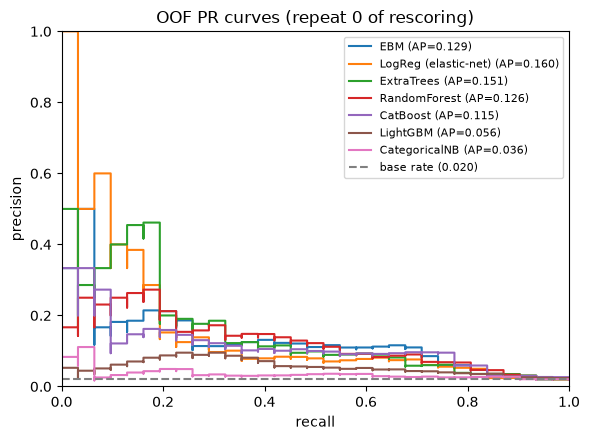

In [ ]:
# Plot all rescored models so weaker ones are visible on the same axes.
top_models = rescore["model"].tolist()
plt.figure(figsize=(6, 4.5))
for name in top_models:
    p = rescore_oof[name][0]
    prec, rec, _ = precision_recall_curve(y_train, p)
    ap = average_precision_score(y_train, p)
    plt.step(rec, prec, where="post", label=f"{name} (AP={ap:.3f})")
plt.axhline(BASE_RATE, color="grey", ls="--", label=f"base rate ({BASE_RATE:.3f})")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("OOF PR curves (repeat 0 of rescoring)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Feature ablation (LogReg)

Same elastic-net LogReg, same CV, on **baseline features only** vs the **full set**.
If the extras do not help, keep the smaller set for the final model.

In [ ]:
# Build baseline matrices aligned with the same rows (after rare-collapse on shared cats).
X_train_base = X_train[BASELINE_CAT + BASELINE_NUM].copy()
X_test_base = X_test[BASELINE_CAT + BASELINE_NUM].copy()

# Retune a LogReg on baseline features only.
rs_base = RandomizedSearchCV(
    make_logreg(cat_cols=BASELINE_CAT, num_cols=BASELINE_NUM),
    {"clf__C": loguniform(0.01, 10.0), "clf__l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0]},
    n_iter=20, scoring="average_precision", cv=tune_cv, n_jobs=-1,
    random_state=RANDOM_STATE, refit=True,
)
rs_base.fit(X_train_base, y_train)
print(f"baseline LogReg best 5-fold AP = {rs_base.best_score_:.3f}")

ap_base, roc_base, oof_base = repeated_cv(
    lambda: clone(rs_base.best_estimator_), X_train_base, y_train,
    n_repeats=N_REPEATS_QUICK, seed=RANDOM_STATE + 101,
)
ap_full, roc_full, oof_full = repeated_cv(
    lambda: clone(tuned["LogReg (elastic-net)"]), X_train, y_train,
    n_repeats=N_REPEATS_QUICK, seed=RANDOM_STATE + 101,
)

ablation = pd.DataFrame([
    {"features": "baseline (M3-like)",
     "ap_mean": ap_base.mean(), "ap_sd": ap_base.std(),
     "roc_mean": roc_base.mean(), "n_features": len(BASELINE_CAT) + len(BASELINE_NUM)},
    {"features": "full (cyclic + calendar + interactions)",
     "ap_mean": ap_full.mean(), "ap_sd": ap_full.std(),
     "roc_mean": roc_full.mean(), "n_features": len(FEATURE_COLS)},
]).round(3)
print("feature ablation (LogReg, same folds):")
ablation

baseline LogReg best 5-fold AP = 0.244
feature ablation (LogReg, same folds):


,features,ap_mean,ap_sd,roc_mean,n_features
0,baseline (M3-like),0.154,0.064,0.839,12
1,full (cyclic + calendar + interactions),0.167,0.089,0.787,23


In [ ]:
# Keep the better feature set for LogReg going forward.
use_full = ap_full.mean() >= ap_base.mean()
if use_full:
    print("→ keeping FULL feature set for LogReg")
    logreg_final_name = "LogReg (elastic-net)"
    X_train_lr, X_test_lr = X_train, X_test
else:
    print("→ switching LogReg to BASELINE features (extras did not help)")
    logreg_final_name = "LogReg (elastic-net, baseline feats)"
    tuned[logreg_final_name] = rs_base.best_estimator_
    # Re-score baseline LogReg into the comparison tables for fairness.
    ap_b, roc_b, oof_b = repeated_cv(
        lambda: clone(rs_base.best_estimator_), X_train_base, y_train,
        n_repeats=N_REPEATS_SELECT, seed=RANDOM_STATE + 101,
    )
    rescore_scores[logreg_final_name] = ap_b
    rescore_oof[logreg_final_name] = oof_b
    # Drop the full-feature LogReg from winner consideration if baseline wins.
    del tuned["LogReg (elastic-net)"]
    X_train_lr, X_test_lr = X_train_base, X_test_base
    # Refresh rescore table.
    rescore_rows = [r for r in rescore_rows if r["model"] != "LogReg (elastic-net)"]
    rescore_rows.append({
        "model": logreg_final_name,
        "ap_mean": ap_b.mean(), "ap_sd": ap_b.std(),
        "ap_median": np.median(ap_b),
        "roc_mean": roc_b.mean(),
        "pooled_oof_ap": pooled_oof_ap(y_train, oof_b),
    })
    rescore = (pd.DataFrame(rescore_rows)
                 .sort_values("ap_mean", ascending=False)
                 .reset_index(drop=True))
    print(rescore.round(3).to_string(index=False))

→ keeping FULL feature set for LogReg


## 7. Winner, threshold, test evaluation

Headline result = CV PR-AUC. Test set has only ~8 positives → treat it as a
sanity check, not the main claim. Threshold = **median** of per-repeat
recall≥0.75 thresholds.

In [ ]:
winner_name = rescore.iloc[0]["model"]
final_model = clone(tuned[winner_name])
print("winner:", winner_name)

# Choose the right X for the winner.
if "baseline" in winner_name:
    Xtr, Xte = X_train_base, X_test_base
elif winner_name.startswith("LogReg") and not use_full:
    Xtr, Xte = X_train_lr, X_test_lr
else:
    Xtr, Xte = X_train, X_test

oof_pool = rescore_oof[winner_name]
thr_recall, thr_list = median_recall_threshold(y_train, oof_pool, target_recall=0.75)
# max-F1 from the pooled first-repeat OOF for comparison
thr_f1, f1_val = best_f1_threshold(y_train, oof_pool[0])
print(f"OOF recall>=0.75 threshold (median over {len(thr_list)} repeats): {thr_recall:.4f}")
print(f"  per-repeat thresholds: {[round(t, 4) for t in thr_list]}")
print(f"OOF max-F1 threshold (repeat 0): {thr_f1:.4f}  (OOF F1 = {f1_val:.3f})")

final_model.fit(Xtr, y_train)
p_test = final_model.predict_proba(Xte)[:, 1]
yhat_recall = (p_test >= thr_recall).astype(int)
yhat_f1 = (p_test >= thr_f1).astype(int)


def _report(name, yhat, thr):
    return {
        "threshold rule": name,
        "threshold": round(thr, 4),
        "test PR-AUC": round(average_precision_score(y_test, p_test), 3),
        "test ROC-AUC": round(roc_auc_score(y_test, p_test), 3),
        "test Brier": round(brier_score_loss(y_test, p_test), 4),
        "test precision": round(precision_score(y_test, yhat, zero_division=0), 3),
        "test recall": round(recall_score(y_test, yhat), 3),
        "test F1": round(f1_score(y_test, yhat, zero_division=0), 3),
        "flagged": int(yhat.sum()),
    }


report = pd.DataFrame([
    _report("recall >= 0.75 (OOF median)", yhat_recall, thr_recall),
    _report("max F1 (OOF repeat 0)", yhat_f1, thr_f1),
])
report

winner: EBM
OOF recall>=0.75 threshold (median over 10 repeats): 0.0299
  per-repeat thresholds: [0.0159, 0.0334, 0.0219, 0.0288, 0.0378, 0.024, 0.0411, 0.0433, 0.0291, 0.0307]
OOF max-F1 threshold (repeat 0): 0.1224  (OOF F1 = 0.219)


,threshold rule,threshold,test PR-AUC,test ROC-AUC,test Brier,test precision,test recall,test F1,flagged
0,recall >= 0.75 (OOF median),0.0299,0.1,0.79,0.0206,0.076,0.625,0.135,66
1,max F1 (OOF repeat 0),0.1224,0.1,0.79,0.0206,0.133,0.250,0.174,15


In [ ]:
for label, yhat, thr in [("recall>=0.75", yhat_recall, thr_recall),
                         ("maxF1", yhat_f1, thr_f1)]:
    cm = confusion_matrix(y_test, yhat)
    print(f"\n{label}  threshold={thr:.3f}")
    print(pd.DataFrame(cm, index=["true 0", "true 1"], columns=["pred 0", "pred 1"]))


recall>=0.75  threshold=0.030
        pred 0  pred 1
true 0     320      61
true 1       3       5

maxF1  threshold=0.122
        pred 0  pred 1
true 0     368      13
true 1       6       2


In [ ]:
lo, hi, boot = bootstrap_metric(y_test, p_test, average_precision_score, n=2000)
print(f"{winner_name}: test PR-AUC = {average_precision_score(y_test, p_test):.3f}  "
      f"[95 % bootstrap CI: {lo:.3f}, {hi:.3f}]  (base rate {y_test.mean():.3f})")
print(f"headline CV PR-AUC = {rescore.iloc[0]['ap_mean']:.3f} ± {rescore.iloc[0]['ap_sd']:.3f}")

EBM: test PR-AUC = 0.100  [95 % bootstrap CI: 0.031, 0.295]  (base rate 0.021)
headline CV PR-AUC = 0.235 ± 0.125


### `tipo_colision` sensitivity check

68 `tipo_colision` values were inferred from `descripcion`. Blank them out and
re-score to confirm the model is not driven by text leakage.

In [ ]:
inferred = pd.read_csv(RAW)["tipo_colision_inferido"].astype(bool)
# Align to the filtered row index of the matrix used by the winner.
mask_inf = inferred.reindex(Xtr.index).fillna(False).astype(bool)
X_noinf = Xtr.copy()
if "tipo_colision" in X_noinf.columns:
    X_noinf.loc[mask_inf, "tipo_colision"] = np.nan

model_noinf = clone(tuned[winner_name])
ap_noinf, _, _ = repeated_cv(lambda: clone(model_noinf), X_noinf, y_train,
                             n_repeats=5, seed=RANDOM_STATE + 101)
print(f"{winner_name} with inferred tipo_colision blanked: "
      f"5x5 PR-AUC = {ap_noinf.mean():.3f} ± {ap_noinf.std():.3f}")
print(f"(original rescore mean = {rescore.iloc[0]['ap_mean']:.3f})")

EBM with inferred tipo_colision blanked: 5x5 PR-AUC = 0.220 ± 0.114
(original rescore mean = 0.235)


## 8. Variable importance

- **Permutation importance on the test set** (not train — avoids rewarding overfit).
- **LogReg odds ratios** for the interpretable story.
- **EBM term importance** if EBM is available.

In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    final_model, Xte, y_test, n_repeats=20,
    random_state=RANDOM_STATE, n_jobs=-1, scoring="average_precision",
)
perm_df = (pd.DataFrame({"feature": Xte.columns,
                         "mean_drop_in_AP": perm.importances_mean,
                         "sd": perm.importances_std})
             .sort_values("mean_drop_in_AP", ascending=False))
perm_df.head(15)

,feature,mean_drop_in_AP,sd
0,tipo_colision,0.016843,0.008218
1,estado_firme,0.015612,0.019019
12,con_pesado,0.012727,0.006783
19,pesados_implicados,0.005899,0.005058
10,dia_semana_cat,0.005809,0.013128
9,mes_cat,0.005565,0.005685
6,distrito,0.001743,0.004687
13,fuera_de_madrid,0.000904,0.005998
16,alcance_tronco,0.000773,0.002876
21,hora_sin,-0.001392,0.005914


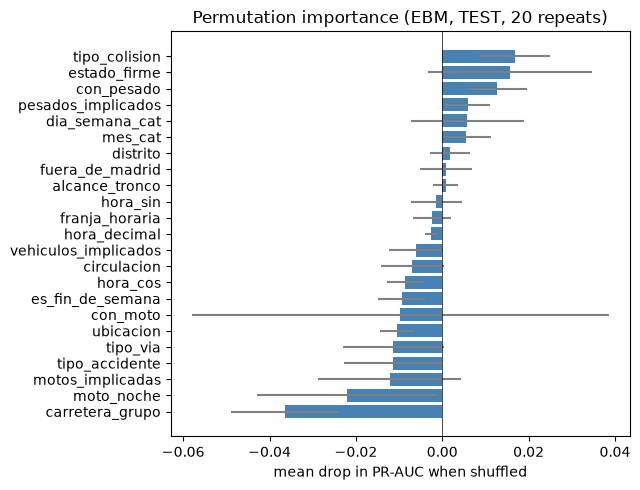

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5))
top = perm_df.iloc[::-1]
ax.barh(top["feature"], top["mean_drop_in_AP"],
        xerr=top["sd"], color="steelblue", ecolor="grey")
ax.axvline(0, color="black", lw=0.5)
ax.set_title(f"Permutation importance ({winner_name}, TEST, 20 repeats)")
ax.set_xlabel("mean drop in PR-AUC when shuffled")
plt.tight_layout()
plt.show()

### Logistic regression odds ratios

OR > 1 raises the odds of a severe outcome (relative to the one-hot baseline).

In [ ]:
# Prefer the LogReg pipeline for explanation even if another model won on score.
lr_name = next((n for n in tuned if n.startswith("LogReg")), None)
if lr_name is not None:
    lr_pipe = clone(tuned[lr_name])
    Xtr_lr = X_train_base if "baseline" in lr_name else X_train
    lr_pipe.fit(Xtr_lr, y_train)
    ohe: OneHotEncoder = lr_pipe.named_steps["pre"].named_transformers_["cat"].named_steps["ohe"]
    cat_used = BASELINE_CAT if "baseline" in lr_name else CAT_COLS
    num_used = BASELINE_NUM if "baseline" in lr_name else NUM_ALL
    cat_names = ohe.get_feature_names_out(cat_used).tolist()
    feat_names = cat_names + num_used
    coefs = lr_pipe.named_steps["clf"].coef_.ravel()
    lr_or = pd.DataFrame({"feature": feat_names, "coef": coefs,
                          "odds_ratio": np.exp(coefs)})
    lr_or["abs_coef"] = lr_or["coef"].abs()
    lr_or = lr_or.sort_values("abs_coef", ascending=False).drop(columns="abs_coef")
    print(f"top drivers from {lr_name} (by |coefficient|):")
    print(lr_or.head(15).to_string(index=False))
else:
    print("no LogReg in tuned set")

top drivers from LogReg (elastic-net) (by |coefficient|):
                                feature      coef  odds_ratio
                   tipo_accidente_Other  2.226666    9.268911
              circulacion_CONGESTIONADA  1.589267    4.900156
                       dia_semana_cat_0 -1.506892    0.221598
                      circulacion_DENSA -1.495896    0.224048
                               con_moto  1.376753    3.962015
                      distrito_SAN BLAS  1.226011    3.407611
                             mes_cat_12  1.201232    3.324211
                       dia_semana_cat_3  1.183812    3.266802
             estado_firme_Seco y limpio  1.141324    3.130912
                   distrito_CARABANCHEL  1.136661    3.116346
                   franja_horaria_noche  1.116832    3.055160
tipo_accidente_Colision entre vehiculos -1.114924    0.327940
                     pesados_implicados -1.086713    0.337323
                       dia_semana_cat_1 -1.083983    0.338246
     tipo_co

### EBM term importance (if tuned)

In [ ]:
if "EBM" in tuned:
    ebm_pipe = clone(tuned["EBM"])
    ebm_pipe.fit(X_train, y_train)
    clf = ebm_pipe.named_steps["clf"]
    # After ordinal encoding the feature order is CAT_COLS + NUM_ALL.
    # EBM term_names_ may be generic; map by position when possible.
    col_names = CAT_COLS + NUM_ALL
    terms = [
        " x ".join(col_names[j] for j in feats)
        for feats in clf.term_features_
    ]
    imp = pd.DataFrame({
        "term": terms,
        "importance": clf.term_importances(),
    }).sort_values("importance", ascending=False)
    print("EBM term importance:")
    print(imp.head(15).to_string(index=False))
else:
    print("EBM not in tuned set")

EBM term importance:
                term  importance
        estado_firme    0.493835
            con_moto    0.452896
      dia_semana_cat    0.269990
            tipo_via    0.243374
    motos_implicadas    0.212858
         circulacion    0.203833
       tipo_colision    0.149908
     carretera_grupo    0.119237
     fuera_de_madrid    0.114621
      tipo_accidente    0.108618
             mes_cat    0.102670
          con_pesado    0.096720
vehiculos_implicados    0.095645
    es_fin_de_semana    0.079452
            hora_sin    0.074608


### Hypotheses from exploration vs model

In [ ]:
hypotheses = [
    ("Motorcycles drive severity", ["con_moto", "motos_implicadas", "moto_noche"]),
    ("Night is riskier",            ["franja_horaria", "hora_sin", "hora_cos", "hora_decimal"]),
    ("Rear-end least severe",       ["tipo_colision", "alcance_tronco"]),
    ("Dense traffic protects",      ["circulacion"]),
]


def total_perm_drop(features):
    return float(perm_df[perm_df["feature"].isin(features)]["mean_drop_in_AP"].sum())


compare = pd.DataFrame([
    {"hypothesis": h, "features": ", ".join(f),
     "sum of permutation drop (test)": round(total_perm_drop(f), 4)}
    for h, f in hypotheses
]).sort_values("sum of permutation drop (test)", ascending=False)
compare

,hypothesis,features,sum of permutation drop (test)
2,Rear-end least severe,"tipo_colision, alcance_tronco",0.0176
3,Dense traffic protects,circulacion,-0.0069
1,Night is riskier,"franja_horaria, hora_sin, hora_cos, hora_decimal",-0.0149
0,Motorcycles drive severity,"con_moto, motos_implicadas, moto_noche",-0.0439


## 9. Findings and limits

**Findings.**

- After dropping `vehiculos_implicados == 0`: 1945 accidents, 39 severe (~2 %);
  train/test = 31 / 8 severe.
- **EBM wins** the 5×10 repeated CV: PR-AUC **0.235 ± 0.125** (base rate 0.02).
  LogReg 0.197, ExtraTrees 0.194, RF 0.188, CatBoost 0.183 are statistically tied;
  LightGBM (0.105) and CategoricalNB (0.063) are clearly worse. EBM beats LogReg on
  70 % of the paired folds (mean gain +0.038, sd 0.109).
- Tuning scores (§4a) are optimistic: LogReg 0.240 in tuning vs 0.197 on fresh folds.
  Only the §5 rescore is used for ranking.
- Feature ablation (§6): full set 0.167 vs baseline 0.154 AP for LogReg (5×5), but
  ROC-AUC drops (0.787 vs 0.839). The extras help ranking only marginally.
- Test PR-AUC **0.100** [95 % CI 0.031–0.295]. At the recall≥0.75 threshold:
  5 / 8 severe caught, 66 / 389 flagged, precision 0.076. Max-F1: 2 / 8 caught, 15 flagged.
- Blanking the 68 text-inferred `tipo_colision` values: 0.220 vs 0.235 AP, so no
  meaningful leakage from `descripcion`.
- Drivers: EBM terms rank `estado_firme`, `con_moto`, `dia_semana_cat`, `tipo_via`;
  LogReg ORs: moto ≈ 4×, night ≈ 3×, rear-end ≈ 0.36×.
  Permutation on the test set disagrees for moto (negative drop): with 8 positives
  that measure is unreliable, so the EBM terms and ORs carry the explanation.

**Limits.**

- ~31 training positives → fold AP sd is large (~0.1). Small score gaps between
  models are not statistically decisive.
- No text (`descripcion` → case 2.1) and no weather / calendar / socio joins
  (cases 1.1 / 1.3).
- Threshold is calibrated on OOF of train; would need re-calibration in production.
- `tipo_accidente == "Otros"` (150 rows) was kept; some are cancelled alerts mixed
  with real motorcycle falls.